# 04 · Perfil de normalidade contextual e decisão Normal/Residual
**CRISP-DM:** Modelagem

**Método proposto (perfil contextual):**
1. Para cada recurso × tipo de dia × hora: mediana e escala robusta (1,4826 × MAD) de cada atributo, com dados de agosto. O tipo de dia é o **adaptado por recurso** decidido no notebook 03: útil / sábado / domingo-feriado onde sábado ≠ domingo; útil / não útil nos demais. O feriado sempre usa o perfil de domingo / não útil.
2. z robusto de cada atributo, contado só na direção desfavorável.
3. **Limite por atributo:** o z de cada atributo é dividido pelo limite daquele atributo no recurso (quantil 99% dos seus z fora da amostra em agosto, mínimo 3). Escore da janela = maior valor normalizado.
4. **Residual** se escore > τ do recurso; τ = quantil 99% dos escores normalizados fora da amostra (meta de 1% de alarmes), mínimo 1.
5. **Fora da amostra = validação cruzada em agosto:** 4 dobras semanais; para cada dobra, o perfil é ajustado nas outras três e pontua a dobra. O perfil final é ajustado com agosto inteiro.

> **Decisões tomadas com o autor durante a execução (iterações do CRISP-DM):**
> - o plano previa calibrar τ só em 25–31/08; com 168 janelas por recurso, 1 ou 2 eventos reais definiam o τ. Passou-se à validação cruzada em agosto (~744 janelas por recurso);
> - com um único τ sobre o maior z, os atributos com picos reais frequentes (taxas de 4xx/5xx) elevavam o τ e escondiam desvios de latência e volume. Passou-se ao **limite por atributo** (passo 3).

Os métodos de comparação (baselines e variantes de contexto) são ajustados e calibrados **exatamente da mesma forma**.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes carregado · raiz: /home/wsl/gh/mestrado/claude9


In [2]:
import pickle
jan = adicionar_tipo_dia_adaptado(pd.read_parquet(RESULTADOS / f"02_janelas_{JANELA}.parquet"))
print("recursos com 3 tipos de dia:", sorted(recursos_3_tipos()))
jan.groupby("recurso")["tipo_dia_ad"].unique()

recursos com 3 tipos de dia: [18139260, 18166630, 18170306, 18917920]


recurso
14553746                   [util, nao_util]
17834257                   [util, nao_util]
18139260    [util, sabado, domingo_feriado]
18166630    [util, sabado, domingo_feriado]
18168196                   [util, nao_util]
18169917                   [util, nao_util]
18170306    [util, sabado, domingo_feriado]
18344302                   [util, nao_util]
18917905                   [util, nao_util]
18917906                   [util, nao_util]
18917920    [util, sabado, domingo_feriado]
18917921                   [util, nao_util]
Name: tipo_dia_ad, dtype: object

## Ajuste e calibração de todos os métodos

In [3]:
ajustados = ajustar_metodos(jan)
taus = pd.DataFrame({nome: a["tau"] for nome, a in ajustados.items()})
taus.round(2)

,Perfil contextual (proposto),Perfil 3 tipos de dia,Perfil 2 tipos de dia,Perfil só hora,Perfil sem feriado,z-score global,Percentil global p1–p99,Semana anterior
14553746,2.17,2.17,2.17,2.26,2.17,2.13,2.66,1.96
17834257,1.35,1.35,1.35,1.35,1.35,1.35,1.39,3.10
18139260,2.05,2.05,2.04,1.64,2.05,1.34,1.70,1.48
18166630,3.27,3.27,2.79,2.57,3.27,1.60,1.65,1.70
18168196,1.82,1.91,1.82,1.88,1.82,1.55,1.97,1.72
18169917,1.62,1.49,1.62,1.52,1.62,1.79,1.84,1.37
18170306,2.25,2.25,2.31,2.17,2.25,1.87,2.19,1.71
18344302,1.72,1.73,1.72,1.79,1.72,1.35,1.45,1.50
18917905,1.86,1.97,1.86,1.99,1.86,1.17,1.27,1.36
18917906,1.73,1.71,1.73,1.64,1.73,1.14,1.19,2.01


### Limite de cada atributo por recurso (método proposto)
Quantil 99% do z de cada atributo fora da amostra em agosto (mínimo 3). Valores altos indicam atributos com picos reais frequentes naquele recurso.

,log_vol,tx_4xx,tx_5xx,log_lat_2xx,log_n_cli,top1_vol,frac_cli_4xx,frac_cli_5xx
14553746,7.2,5.1,16.9,7.6,6.4,3.0,3.0,13.4
17834257,14.2,3.0,22.2,4.3,3.0,3.0,3.0,33.3
18139260,7.2,14.7,3.0,8.0,10.3,5.2,4.3,3.0
18166630,7.9,4.3,3.0,3.9,4.0,3.0,4.7,6.7
18168196,9.5,4.5,3.0,7.8,4.5,3.2,16.7,8.3
18169917,9.9,7.1,3.0,7.3,3.7,7.4,7.2,9.3
18170306,4.7,46.4,4.1,11.0,4.1,3.2,7.7,9.8
18344302,7.2,85.9,3.0,9.5,5.1,3.0,18.6,12.4
18917905,22.2,3.0,3.0,5.7,5.3,14.5,3.1,5.6
18917906,10.2,3.6,3.0,14.6,4.2,3.8,3.2,3.3


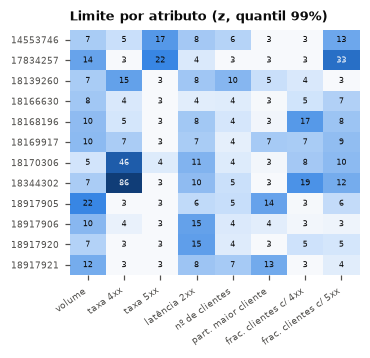

In [4]:
limite = ajustados[PROPOSTO]["limite"]
display(limite.round(1))
fig, ax = plt.subplots(figsize=(3.4, 2.9))
v = np.log10(limite.to_numpy())
ax.imshow(v, cmap=CMAP_SEQ, vmin=np.log10(3), vmax=2, aspect="auto")
for i in range(v.shape[0]):
    for j in range(v.shape[1]):
        x = limite.iat[i, j]
        ax.text(j, i, f"{x:.0f}", ha="center", va="center", fontsize=5.5, color="white" if v[i, j] > 1.4 else TXT1)
ax.set_xticks(range(len(ATRIBUTOS)))
ax.set_xticklabels([NOMES[a] for a in ATRIBUTOS], rotation=35, ha="right", fontsize=6)
ax.set_yticks(range(len(limite)))
ax.set_yticklabels(limite.index, fontsize=6)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Limite por atributo (z, quantil 99%)", loc="left")
salvar(fig, "fig_limites_atributo")
plt.show()

O τ (sobre o escore normalizado) indica quanto, além do limite de cada atributo, as janelas de agosto chegaram em 1% dos casos.

In [5]:
print("quantis do escore normalizado fora da amostra (método proposto), por recurso:")
a = ajustados[PROPOSTO]
display(a["escores_cal"].groupby(a["recursos_cal"].to_numpy()).quantile([0.5, 0.9, 0.95, 0.99]).unstack().round(1))
alarmes_cal = pd.DataFrame({nome: (a["escores_cal"] > a["tau"].reindex(a["recursos_cal"]).to_numpy()).groupby(a["recursos_cal"].to_numpy()).mean()
                            for nome, a in ajustados.items()})
print("fração das janelas de agosto (fora da amostra) marcadas como Residual (média por recurso):")
alarmes_cal.mean().round(4)

quantis do escore normalizado fora da amostra (método proposto), por recurso:


,0.50,0.90,0.95,0.99
14553746,0.3,0.8,1.0,2.2
17834257,0.4,0.9,1.0,1.4
18139260,0.3,0.9,1.1,2.0
18166630,0.4,0.8,1.1,3.3
18168196,0.4,0.9,1.1,1.8
18169917,0.4,0.9,1.1,1.6
18170306,0.4,0.9,1.1,2.2
18344302,0.4,0.9,1.1,1.7
18917905,0.3,0.8,1.0,1.9
18917906,0.4,0.9,1.1,1.7


fração das janelas de agosto (fora da amostra) marcadas como Residual (média por recurso):


Perfil contextual (proposto)    0.0103
Perfil 3 tipos de dia           0.0100
Perfil 2 tipos de dia           0.0103
Perfil só hora                  0.0102
Perfil sem feriado              0.0103
z-score global                  0.0101
Percentil global p1–p99         0.0106
Semana anterior                 0.0078
dtype: float64

## Perfil do método proposto: exemplo de faixas normais
Faixa p5–p95 e mediana do volume por hora, por tipo de dia, para um recurso com três tipos de dia.

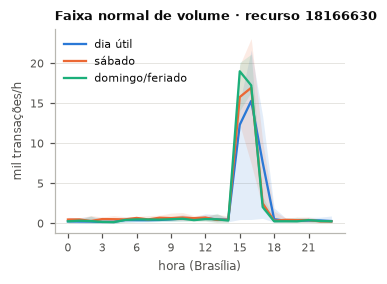

In [6]:
perfil = ajustados[PROPOSTO]["modelo"]
r_ex = 18166630  # recurso com 3 tipos de dia e lote às 15–16h
m = perfil.mediana.loc[r_ex]["log_vol"].unstack(0)
lo, hi = perfil.q05.loc[r_ex]["log_vol"].unstack(0), perfil.q95.loc[r_ex]["log_vol"].unstack(0)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for td in [t for t in TIPOS_ORDEM if t in m.columns]:
    cor = COR_DIA.get(td, CORES[3])
    ax.fill_between(m.index, np.expm1(lo[td]) / 1000, np.expm1(hi[td]) / 1000, color=cor, alpha=0.13, lw=0)
    ax.plot(m.index, np.expm1(m[td]) / 1000, color=cor, lw=1.5, label=NOMES_DIA[td])
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hora (Brasília)")
ax.set_ylabel("mil transações/h")
ax.set_title(f"Faixa normal de volume · recurso {r_ex}", loc="left")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
salvar(fig, "fig_faixa_normal")
plt.show()

## Residual em agosto fora da amostra (dados reais, sem injeção)
Sequências de janelas residuais do método proposto na validação cruzada de agosto, com o atributo de maior desvio e o lado provável. Servem para inspecionar o método em dados reais: são candidatas a anomalias reais ou a variações normais raras.

In [7]:
tr = recortar(jan, TREINO).copy()
dobra = dobras_semanais(tr)
zs = pd.DataFrame(index=tr.index, columns=ATRIBUTOS, dtype=float)
for k in range(4):
    m = PerfilContextual(("tipo_dia_ad", "hora")).ajustar(tr[dobra != k])
    zs.loc[dobra == k] = m.z(tr[dobra == k]).to_numpy()
trj, zs = tr.reset_index(drop=True), zs.reset_index(drop=True)
zn = z_direcional(zs) / ajustados[PROPOSTO]["limite"].reindex(trj["recurso"]).to_numpy()
esc = zn.max(axis=1)
tau_p = ajustados[PROPOSTO]["tau"]
res = (esc > tau_p.reindex(trj["recurso"]).to_numpy()).to_numpy()
seq = sequencias(res, trj["recurso"])
poucos = recursos_poucos_clientes(tr)
linhas = []
for s_id in np.unique(seq[seq >= 0]):
    idx = np.flatnonzero(seq == s_id)
    top = idx[np.argmax(esc.to_numpy()[idx])]
    lado, regra = lado_provavel(zn.iloc[top], zs.iloc[top], trj.iloc[top], trj.loc[top, "recurso"] in poucos)
    linhas.append(dict(recurso=trj.loc[top, "recurso"], inicio=trj.loc[idx[0], "janela"], janelas=len(idx),
                       atributo=NOMES[zn.iloc[top].idxmax()], escore=round(esc.iloc[top], 2), lado=lado, regra=regra))
res_cal = pd.DataFrame(linhas)
print(len(res_cal), "sequências residuais em agosto;", "duração (janelas):", res_cal["janelas"].value_counts().to_dict())
display(res_cal.groupby("atributo").size().sort_values(ascending=False).rename("sequências"))
display(res_cal.groupby("lado").size().rename("sequências"))
res_cal.sort_values("escore", ascending=False).head(15)

68 sequências residuais em agosto; duração (janelas): {1: 55, 2: 6, 3: 4, 4: 2, 5: 1}


atributo
latência 2xx             15
taxa 5xx                 13
volume                   11
taxa 4xx                  9
frac. clientes c/ 5xx     8
part. maior cliente       6
frac. clientes c/ 4xx     5
nº de clientes            1
Name: sequências, dtype: int64

lado
consumidor       26
indeterminado     6
provedor         36
Name: sequências, dtype: int64

,recurso,inicio,janelas,atributo,escore,lado,regra
15,18166630,2026-08-22 15:00:00,2,taxa 4xx,22.22,provedor,4xx elevado e espalhado entre clientes
36,18170306,2026-08-27 08:00:00,1,taxa 5xx,20.12,provedor,5xx elevado e espalhado entre clientes
35,18170306,2026-08-26 08:00:00,2,taxa 5xx,20.00,provedor,5xx elevado e espalhado entre clientes
11,18166630,2026-08-01 21:00:00,1,taxa 4xx,15.58,consumidor,4xx elevado e concentrado em até 2 clientes
24,18169917,2026-08-09 01:00:00,2,taxa 5xx,12.01,consumidor,5xx elevado e concentrado em até 2 clientes
17,18168196,2026-08-03 00:00:00,3,taxa 4xx,9.94,provedor,4xx elevado e espalhado entre clientes
47,18917905,2026-08-09 02:00:00,3,taxa 5xx,9.20,consumidor,5xx elevado e concentrado em até 2 clientes
38,18344302,2026-08-09 02:00:00,1,taxa 5xx,8.33,consumidor,5xx elevado e concentrado em até 2 clientes
0,14553746,2026-08-09 02:00:00,1,latência 2xx,8.18,provedor,latência 2xx elevada
66,18917921,2026-08-09 02:00:00,3,taxa 5xx,7.47,consumidor,5xx elevado e concentrado em até 2 clientes


In [8]:
with open(RESULTADOS / "04_modelos.pkl", "wb") as f:
    pickle.dump(ajustados, f)
taus.to_csv(RESULTADOS / "04_taus.csv")
res_cal.to_csv(RESULTADOS / "04_residual_calibracao.csv", index=False)
limite.to_csv(RESULTADOS / "04_limites_atributo.csv")
salvar_json(dict(tau_proposto=tau_p.to_dict(), tau_mediana=float(tau_p.median()),
                 n_sequencias_agosto=len(res_cal), sequencias_1_janela=int((res_cal["janelas"] == 1).sum()),
                 alarmes_calibracao=alarmes_cal.mean().to_dict(), poucos_clientes=sorted(int(r) for r in poucos)),
            "04_resumo.json")